# Rohini AQI: Next-Day Prediction (Jupyter Notebook)



## 1. Install and import libraries

Run the installation cell once in your VS Code notebook environment.

In [1]:
%pip install pandas numpy matplotlib scikit-learn openpyxl joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import zipfile
import csv
import re
import calendar
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import joblib

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

## 2. Locate and extract the datasets



In [3]:
ZIP_PATH = Path("ml project datasets(2).zip")
EXTRACT_DIR = Path("project_data")

if not ZIP_PATH.exists():
    raise FileNotFoundError(
        f"Cannot find {ZIP_PATH.resolve()}. Put the ZIP beside this notebook "
        "or update ZIP_PATH to its location."
    )

EXTRACT_DIR.mkdir(exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as outer_zip:
    outer_zip.extractall(EXTRACT_DIR)

# The daily spreadsheets are stored inside archive.zip in the uploaded ZIP.
nested_archives = list(EXTRACT_DIR.rglob("archive.zip"))
for nested_path in nested_archives:
    nested_dir = nested_path.parent / "archive_contents"
    nested_dir.mkdir(exist_ok=True)
    with zipfile.ZipFile(nested_path, "r") as nested_zip:
        nested_zip.extractall(nested_dir)

print("Extracted data under:", EXTRACT_DIR.resolve())
for p in sorted(EXTRACT_DIR.rglob("*")):
    if p.is_file():
        print("-", p.relative_to(EXTRACT_DIR))

Extracted data under: C:\Users\Shivanshika\Downloads\Rohini_AQI_Jupyter_Project\Rohini_AQI_Project\project_data
- ml project datasets\10f87d38-a3a3-4883-af10-35c05dce8292.csv
- ml project datasets\archive.zip
- ml project datasets\archive_contents\Cleaned_NSUT.xlsx
- ml project datasets\archive_contents\final_dataset.csv
- ml project datasets\archive_contents\FINAL_ITO_DATA.xlsx
- ml project datasets\del-ito-cpcb-2024-25.csv


## 3. Inspect the datasets and their station labels


In [4]:
all_files = [p for p in EXTRACT_DIR.rglob("*") if p.is_file()]
for p in all_files:
    print(f"{p.name:45s} {p.stat().st_size:>12,} bytes")

# Inspect the daily AQI datasets
daily_files = (
    list(EXTRACT_DIR.rglob("Cleaned_NSUT.xlsx"))
    + list(EXTRACT_DIR.rglob("FINAL_ITO_DATA.xlsx"))
    + list(EXTRACT_DIR.rglob("final_dataset.csv"))
)

for file_path in daily_files:
    if file_path.suffix.lower() == ".xlsx":
        temp = pd.read_excel(file_path)
    else:
        temp = pd.read_csv(file_path)
    print(f"\n{file_path.name}: {temp.shape}")
    print("Columns:", temp.columns.tolist())
    print(temp.head(2))

# Inspect station labels in the 15-minute CPCB file
ito_files = list(EXTRACT_DIR.rglob("del-ito-cpcb-2024-25.csv"))
if ito_files:
    ito = pd.read_csv(ito_files[0], nrows=5)
    print("\nStation information in the 15-minute file:")
    print(ito[["State", "City", "Station Name"]].drop_duplicates())

10f87d38-a3a3-4883-af10-35c05dce8292.csv           286,990 bytes
archive.zip                                        253,761 bytes
del-ito-cpcb-2024-25.csv                         9,463,652 bytes
Cleaned_NSUT.xlsx                                  109,272 bytes
final_dataset.csv                                   78,368 bytes
FINAL_ITO_DATA.xlsx                                119,476 bytes

Cleaned_NSUT.xlsx: (1461, 12)
Columns: ['Date', 'Month', 'Year', 'Holidays_Count', 'Days', 'PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'Ozone', 'AQI']
   Date  Month  Year  Holidays_Count  Days   PM2.5    PM10    NO2    SO2  \
0     1      1  2021               0     5  180.57  458.90  42.35  10.03   
1     2      1  2021               0     6  146.71  371.52  27.41  10.05   

     CO  Ozone    AQI  
0  1.57  19.04  336.0  
1  1.14  13.37  351.0  

FINAL_ITO_DATA.xlsx: (1461, 12)
Columns: ['Date', 'Month', 'Year', 'Holidays_Count', 'Days', 'PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'Ozone', 'AQI']
   Date  Month  Y

## 4. Convert the hourly AQI matrix into a time series



In [5]:
hourly_candidates = [
    p for p in EXTRACT_DIR.rglob("*.csv")
    if p.name != "del-ito-cpcb-2024-25.csv"
    and p.name != "final_dataset.csv"
]

print("Possible hourly CSV files:")
for p in hourly_candidates:
    print("-", p)

Possible hourly CSV files:
- project_data\ml project datasets\10f87d38-a3a3-4883-af10-35c05dce8292.csv


In [6]:
def parse_monthly_hourly_aqi(csv_path):
    """Parse a month/day/24-hour AQI matrix into timestamped hourly rows."""
    records = []
    current_year = None
    current_month = None

    with open(csv_path, "r", encoding="utf-8-sig", newline="") as f:
        reader = csv.reader(f)
        for row in reader:
            if not row:
                continue

            first = str(row[0]).strip().strip('"')

            # Year header, e.g. Year,2017
            if first.lower() == "year":
                if len(row) > 1 and str(row[1]).strip().isdigit():
                    current_year = int(str(row[1]).strip())
                continue

            # Month header, e.g. January-2017,00:00:00,...
            month_match = re.fullmatch(r"([A-Za-z]+)-(20\d{2})", first)
            if month_match:
                current_month = list(calendar.month_name).index(month_match.group(1).capitalize())
                current_year = int(month_match.group(2))
                continue

            # Ignore separator rows such as a lone quote.
            if not first.isdigit() or current_year is None or current_month is None:
                continue

            day = int(first)
            if not 1 <= day <= calendar.monthrange(current_year, current_month)[1]:
                continue

            values = row[1:25]
            for hour, value in enumerate(values):
                value = str(value).strip().strip('"')
                if value in ("", "nan", "NaN", "None"):
                    continue
                try:
                    aqi_value = float(value)
                except ValueError:
                    continue

                timestamp = pd.Timestamp(
                    year=current_year, month=current_month, day=day, hour=hour
                )
                records.append({"timestamp": timestamp, "hourly_aqi": aqi_value})

    result = pd.DataFrame(records)
    if result.empty:
        raise ValueError("No hourly AQI values could be parsed. Check the CSV layout.")
    result = (
        result.drop_duplicates("timestamp")
              .sort_values("timestamp")
              .reset_index(drop=True)
    )
    return result


if not hourly_candidates:
    raise FileNotFoundError("No candidate hourly CSV was found in the extracted archive.")

# In this uploaded archive there is one non-ITO, non-final-daily CSV candidate.
hourly_file = hourly_candidates[0]
hourly_data = parse_monthly_hourly_aqi(hourly_file)

print("Parsed file:", hourly_file.name)
print("Hourly rows:", len(hourly_data))
print("Date range:", hourly_data["timestamp"].min(), "to", hourly_data["timestamp"].max())
display(hourly_data.head())

Parsed file: 10f87d38-a3a3-4883-af10-35c05dce8292.csv
Hourly rows: 47486
Date range: 2018-02-01 11:00:00 to 2023-12-31 23:00:00


,timestamp,hourly_aqi
0,2018-02-01 11:00:00,453.0
1,2018-02-01 12:00:00,408.0
2,2018-02-01 13:00:00,333.0
3,2018-02-01 14:00:00,302.0
4,2018-02-01 15:00:00,253.0


## 5. Create daily AQI values

For this first model, we calculate the **mean of the available hourly AQI readings for each date**. This makes the target explicit and reproducible. It should not be described as an official CPCB daily AQI calculation.

In [7]:
daily_aqi = (
    hourly_data.set_index("timestamp")["hourly_aqi"]
    .resample("D")
    .agg(["mean", "max", "count"])
    .rename(columns={
        "mean": "AQI",
        "max": "daily_max_hourly_AQI",
        "count": "valid_hourly_readings"
    })
    .reset_index()
    .rename(columns={"timestamp": "date"})
)

# Keep dates with at least one hourly reading.
daily_aqi = daily_aqi.dropna(subset=["AQI"]).copy()
daily_aqi["date"] = pd.to_datetime(daily_aqi["date"])
display(daily_aqi.head())
print("Daily rows:", len(daily_aqi))
print("Date range:", daily_aqi.date.min(), "to", daily_aqi.date.max())

,date,AQI,daily_max_hourly_AQI,valid_hourly_readings
0,2018-02-01,348.384615,487.0,13
1,2018-02-02,266.285714,464.0,21
2,2018-02-03,292.458333,472.0,24
3,2018-02-04,315.166667,466.0,24
4,2018-02-05,369.541667,476.0,24


Daily rows: 2138
Date range: 2018-02-01 00:00:00 to 2023-12-31 00:00:00


## 6. Confirm the station before training



In [8]:
HOURLY_FILE_CONFIRMED_AS_ROHINI = True  # Change to True only after source confirmation.

if not HOURLY_FILE_CONFIRMED_AS_ROHINI:
    raise RuntimeError(
        "Training stopped to prevent a wrong-location model. "
        "Confirm that the hourly AQI CSV is from the Rohini monitoring station, "
        "then set HOURLY_FILE_CONFIRMED_AS_ROHINI = True and rerun this cell."
    )

print("Station confirmation flag is enabled. Proceeding with the hourly AQI series.")

Station confirmation flag is enabled. Proceeding with the hourly AQI series.


## 7. Prepare next-day forecasting examples

Each training row uses only information available up to a particular day. Its target is the following day's average hourly AQI.

We use recent AQI lags, rolling averages, and calendar features. No future day's AQI or pollutant measurements are used as inputs.

In [9]:
def make_supervised_data(daily):
    data = daily[["date", "AQI"]].copy().sort_values("date").reset_index(drop=True)

    # Lags: lag_1 is the most recently observed day (the day before the target).
    X = pd.DataFrame(index=data.index)
    for lag in [1, 2, 3, 7, 14]:
        X[f"AQI_lag_{lag}"] = data["AQI"].shift(lag - 1)

    for window in [3, 7, 14]:
        X[f"AQI_rolling_mean_{window}"] = data["AQI"].rolling(window).mean()

    target_dates = data["date"].shift(-1)
    X["target_month"] = target_dates.dt.month
    X["target_day_of_week"] = target_dates.dt.dayofweek
    X["target_day_of_year_sin"] = np.sin(2 * np.pi * target_dates.dt.dayofyear / 365.25)
    X["target_day_of_year_cos"] = np.cos(2 * np.pi * target_dates.dt.dayofyear / 365.25)

    y = data["AQI"].shift(-1).rename("AQI_next_day")
    target_dates = target_dates.rename("target_date")

    combined = X.copy()
    combined["target_date"] = target_dates
    combined["AQI_next_day"] = y
    combined = combined.dropna().reset_index(drop=True)

    X_final = combined.drop(columns=["target_date", "AQI_next_day"])
    y_final = combined["AQI_next_day"]
    dates_final = combined["target_date"]
    return X_final, y_final, dates_final


X, y, target_dates = make_supervised_data(daily_aqi)

if len(X) < 100:
    raise ValueError("Not enough training examples. Check the hourly dataset coverage.")

print("Supervised examples:", len(X))
print("First target date:", target_dates.min())
print("Last target date:", target_dates.max())

Supervised examples: 2124
First target date: 2018-02-15 00:00:00
Last target date: 2023-12-31 00:00:00


## 8. Chronological train/test split and model comparison

We do not randomly shuffle time-series data. The earlier 80% is used for training and the latest 20% for testing, simulating prediction on future dates.

In [10]:
split_index = int(len(X) * 0.80)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]
test_dates = target_dates.iloc[split_index:]

models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.04, max_depth=2, random_state=42
    )
}

results = []
fitted_models = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    fitted_models[name] = model
    predictions[name] = pred

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

comparison = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
display(comparison)

best_model_name = comparison.loc[0, "Model"]
best_model = fitted_models[best_model_name]
print("Selected model:", best_model_name)

,Model,MAE,RMSE,R2
0,Linear Regression,38.110927,52.500347,0.804896
1,Gradient Boosting,38.435978,52.375283,0.805825
2,Random Forest,39.269486,53.831452,0.794877


Selected model: Linear Regression


## 9. Plot actual vs predicted AQI

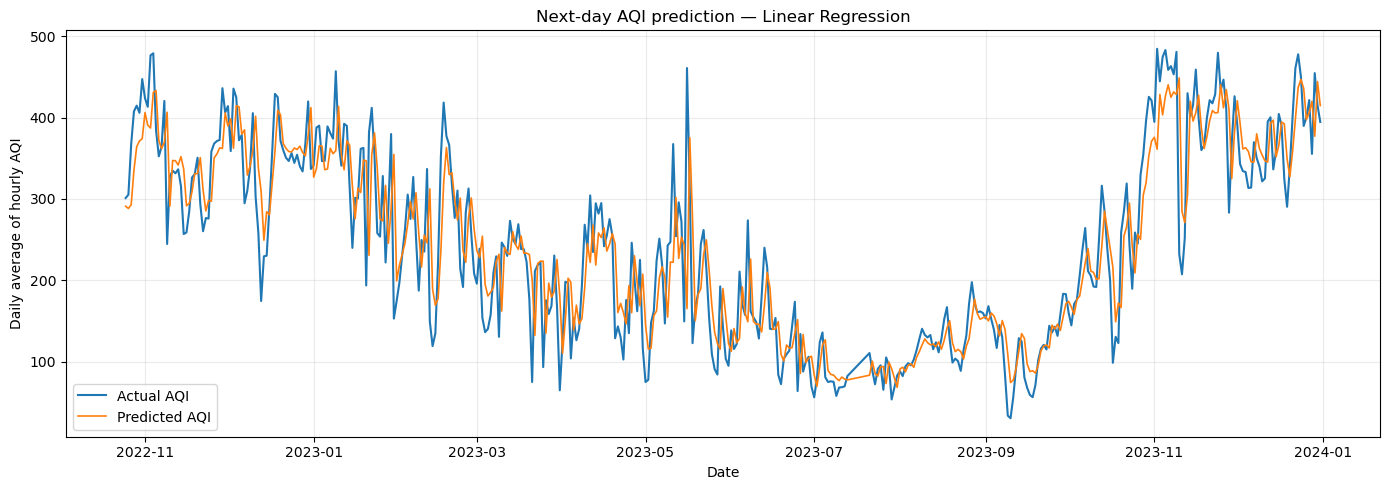

In [11]:
best_predictions = predictions[best_model_name]

plt.figure(figsize=(14, 5))
plt.plot(test_dates, y_test.values, label="Actual AQI", linewidth=1.5)
plt.plot(test_dates, best_predictions, label="Predicted AQI", linewidth=1.2)
plt.title(f"Next-day AQI prediction — {best_model_name}")
plt.xlabel("Date")
plt.ylabel("Daily average of hourly AQI")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 10. Predict the next day and save the model

The prediction uses the latest available daily AQI history. The forecast date is one calendar day after the latest date in the dataset.

In [12]:
def make_next_day_features(daily):
    data = daily[["date", "AQI"]].copy().sort_values("date").reset_index(drop=True)

    if len(data) < 14:
        raise ValueError("At least 14 daily records are required for the selected lag features.")

    latest_date = data["date"].iloc[-1]
    prediction_date = latest_date + pd.Timedelta(days=1)

    row = {}
    for lag in [1, 2, 3, 7, 14]:
        row[f"AQI_lag_{lag}"] = data["AQI"].iloc[-lag]

    for window in [3, 7, 14]:
        row[f"AQI_rolling_mean_{window}"] = data["AQI"].tail(window).mean()

    row["target_month"] = prediction_date.month
    row["target_day_of_week"] = prediction_date.dayofweek
    row["target_day_of_year_sin"] = np.sin(2 * np.pi * prediction_date.dayofyear / 365.25)
    row["target_day_of_year_cos"] = np.cos(2 * np.pi * prediction_date.dayofyear / 365.25)

    return pd.DataFrame([row])[X.columns], prediction_date


X_next, prediction_date = make_next_day_features(daily_aqi)
next_day_prediction = float(best_model.predict(X_next)[0])

print(f"Latest available data: {daily_aqi['date'].max().date()}")
print(f"Predicted AQI for: {prediction_date.date()}")
print(f"Predicted daily average hourly AQI: {next_day_prediction:.1f}")

# Save outputs and trained model beside the notebook.
OUTPUT_DIR = Path("outputs")
MODEL_DIR = Path("models")
OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
daily_aqi.to_csv(OUTPUT_DIR / "rohini_daily_aqi.csv", index=False)
joblib.dump(best_model, MODEL_DIR / "best_rohini_aqi_model.joblib")

with open(MODEL_DIR / "feature_columns.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(X.columns))

print("Saved model and outputs.")

Latest available data: 2023-12-31
Predicted AQI for: 2024-01-01
Predicted daily average hourly AQI: 376.5
Saved model and outputs.
